<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-017-autoencoders-anomaly-detection.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 017 
<hr/>

# Lab 017 — Autoencoders and anomaly detection

Until now every image came with a label. Here we keep only the images $\{\mathbf x_i\}_{i=1}^n$ and let a network learn to **compress** them: an autoencoder squeezes each image through a narrow layer of $d$ numbers and rebuilds it. Both what it keeps in those $d$ numbers and what it fails to rebuild turn out to be useful.

We first define the autoencoder, its encoder, decoder and bottleneck, and its pixel-by-pixel loss, and show that a *linear* autoencoder rediscovers principal component analysis (PCA). Dense autoencoders on MNIST (the handwritten digits of Lab 016) follow, with $d=2$, a latent space we can draw, and with $d=16$; we compare them with PCA, computed in JAX and with scikit-learn. The 16 latent numbers form a new data set, which we look at with PCA and with t-SNE (t-distributed stochastic neighbour embedding, a non-linear map that keeps neighbours) and cluster with k-means (groups around $k$ centres); both methods are derived and implemented in Lab 016. Convolutional autoencoders, a small one with $d=2$ and a deeper one with batch normalisation and $d=16$, use the two-dimensional structure of the images. The reconstruction error then becomes an anomaly score: an autoencoder trained on all digits except the 7s should rebuild the 7s worse, and we measure how well this finds them with the receiver operating characteristic (ROC) curve and the area under it (AUC), implemented in JAX and compared with scikit-learn. Finally, CIFAR-10 photographs (a data set of the Canadian Institute For Advanced Research: $32\times32$ colour images in 10 classes) show the limits of a pixel-wise loss and serve as a clear anomaly for the MNIST autoencoder.

The networks are built with `flax.nnx` and trained with `optax`, with one jit-compiled JAX function per training epoch. scikit-learn provides t-SNE, k-means and the cross-checks of PCA and of the ROC analysis.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The notebook runs on the **CPU** (central processing unit) (the first code cell sets `JAX_PLATFORMS=cpu`); the training sets and numbers of epochs are chosen so that it finishes in a reasonable time on a multi-core CPU. With a GPU (graphics processing unit) runtime you can delete that line and train the larger models on more data.
> 2. `jax`, `flax`, `optax`, `scikit-learn` and `matplotlib` are pre-installed in Colab; the stored outputs were produced with scikit-learn 1.6.1.
> 3. The notebook uses MNIST and CIFAR-10; if the files are missing, it downloads them.
> 4. Run the cells *in order*: later cells use variables defined earlier. If the state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import gzip, json, pickle, tarfile, time, urllib.request
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

import jax, jax.numpy as jnp
import optax
from flax import nnx
import flax

import sklearn                              # scikit-learn: the outputs below were produced with version 1.6.1
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE          # t-SNE and k-means of the latent spaces (Lab 016 explains both methods)
from sklearn.cluster import KMeans
from sklearn import metrics                # metrics.roc_curve, metrics.roc_auc_score (our own roc_curve is defined below)
from sklearn.metrics import adjusted_rand_score

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
cmap10 = plt.get_cmap("tab10")
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0})
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# figures for the slides are drawn at their printed size (slide text width 5.5 in) with 10-11 pt text
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
            "legend.fontsize": 10, "lines.linewidth": 1.5, "axes.linewidth": 0.8, "xtick.major.size": 3,
            "ytick.major.size": 3, "axes.labelpad": 2, "axes.titlepad": 4}
OUTLINE = [pe.withStroke(linewidth=2.5, foreground="white")]   # white edge around labels drawn on top of points

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def noframe(ax):                          # image panels: no ticks, no frame
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
def save(fig, name, **kw):
    fig.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight", **kw)

nums = {}                                 # numbers quoted on the slides
t_start = time.time()
print("JAX", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__, "| scikit-learn", sklearn.__version__)
print("devices:", jax.devices())

JAX 0.11.0 | flax 0.12.8 | optax 0.2.6 | scikit-learn 1.6.1
devices: [CpuDevice(id=0)]


<hr/>
## 1. The data

MNIST (Modified National Institute of Standards and Technology database): $28\times28$ grayscale digits, $60\,000$ for training and $10\,000$ for testing. Each image is a vector $\mathbf x\in[0,1]^{D}$ with $D=784$ pixels. The files are in the raw IDX format, a simple binary format for multi-dimensional arrays: a short big-endian header (a magic number, then the sizes), followed by one byte per pixel. We read them with `gzip` and `numpy` only.

For the plots of latent spaces we use a fixed random subset of $5000$ test images (`X5`, `y5`).

train (60000, 784) test (10000, 784) plot subset (5000, 784) | pixel range 0.0 1.0


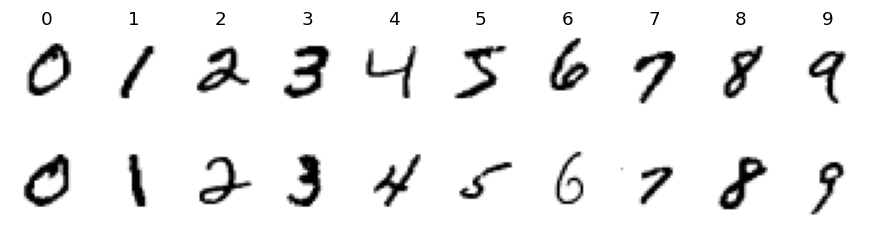

In [2]:
MNIST_DIR = "data/MNIST_raw"
MNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
               "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
if not all(os.path.exists(f"{MNIST_DIR}/{f}") for f in MNIST_FILES):
    os.makedirs(MNIST_DIR, exist_ok=True)
    for f in MNIST_FILES:
        urllib.request.urlretrieve(f"https://storage.googleapis.com/cvdf-datasets/mnist/{f}", f"{MNIST_DIR}/{f}")

def read_idx(path):
    with gzip.open(path, "rb") as fh:
        data = fh.read()
    ndim = data[3]                                                  # 3 for images, 1 for labels
    shape = np.frombuffer(data[4:4 + 4 * ndim], dtype=">i4")        # big-endian int32 sizes
    return np.frombuffer(data[4 + 4 * ndim:], dtype=np.uint8).reshape(shape)

Xtr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[0]}").reshape(-1, 784).astype(np.float32) / 255.0
ytr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[1]}").astype(np.int32)
Xte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[2]}").reshape(-1, 784).astype(np.float32) / 255.0
yte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[3]}").astype(np.int32)

rng = np.random.default_rng(0)
sel = rng.choice(len(Xte), 5000, replace=False)                     # fixed subset of test digits for plots
X5, y5 = Xte[sel], yte[sel]
print("train", Xtr.shape, "test", Xte.shape, "plot subset", X5.shape, "| pixel range", Xtr.min(), Xtr.max())

fig, axs = plt.subplots(2, 10, figsize=(10, 2.4))
for d in range(10):
    for r in range(2):
        axs[r, d].imshow(Xtr[np.flatnonzero(ytr == d)[r]].reshape(28, 28), cmap="gray_r"); axs[r, d].axis("off")
    axs[0, d].set_title(str(d), fontsize=12)
plt.show()

Before training we move the data to the device. `jnp.asarray` copies a NumPy array to the default device (here the CPU; on a GPU runtime, the GPU), and we do this once for the whole training set. Later a minibatch is taken *on the device* by indexing, `X[idx]`, so that on a GPU no data travel between host and device during training. JAX arrays are immutable: we never modify them in place, we create new ones.

In [3]:
Xtr_d = jnp.asarray(Xtr)                 # (60000, 784) on the default device
Xte_d = jnp.asarray(Xte)
X5_d = jnp.asarray(X5)
print(Xtr_d.devices(), Xtr_d.dtype, f"{Xtr_d.nbytes / 1e6:.0f} MB")

{CpuDevice(id=0)} float32 188 MB


<hr/>
## 2. The autoencoder

An autoencoder is two neural networks trained together:

* an **encoder** $E_{\boldsymbol\theta_E}:\mathbb R^{D}\to\mathbb R^{d}$ with $D$ inputs (the size of the data, $784$ pixels), $d$ outputs (the latent-space size, chosen by us) and its own parameters $\boldsymbol\theta_E$ (weights and biases). Its output $\mathbf z=E_{\boldsymbol\theta_E}(\mathbf x)$ is the **latent vector**;
* a **decoder** $G_{\boldsymbol\theta_D}:\mathbb R^{d}\to\mathbb R^{D}$ with $d$ inputs, $D$ outputs and its own parameters $\boldsymbol\theta_D$. Its output $\hat{\mathbf x}=G_{\boldsymbol\theta_D}(\mathbf z)$ is the **reconstruction**.

$$
\mathbf x\in\mathbb R^{784}\ \xrightarrow{\ E_{\boldsymbol\theta_E}\ }\ \mathbf z\in\mathbb R^{d}\ \xrightarrow{\ G_{\boldsymbol\theta_D}\ }\ \hat{\mathbf x}\in\mathbb R^{784}
$$

### The loss, pixel by pixel

There are no labels: every input is its own target. The loss compares each image with its reconstruction **pixel by pixel**,
$$
\mathcal L(\boldsymbol\theta_E,\boldsymbol\theta_D)=\frac1n\sum_{i=1}^{n}\underbrace{\frac1D\sum_{j=1}^{D}\big(x_{ij}-\hat x_{ij}\big)^2}_{e(\mathbf x_i)},\qquad \hat{\mathbf x}_i=G_{\boldsymbol\theta_D}\big(E_{\boldsymbol\theta_E}(\mathbf x_i)\big),
$$
with $i$ the image and $j$ the pixel. Two levels of averaging appear here, and both are used below:

* $e(\mathbf x)=\frac1D\lVert\mathbf x-\hat{\mathbf x}\rVert^2$ is the **reconstruction error of one image**, the mean of the per-pixel squared differences $(x_j-\hat x_j)^2$. A map of these $784$ numbers shows *where* the image is rebuilt badly. Later, $e(\mathbf x)$ will be our **anomaly score**.
* $\mathcal L$, the average of $e$ over the images, is the **mean squared error (MSE)** over all $n\cdot D$ pixel values. It is the number we minimise, and the number we report as the "test MSE".

$\mathcal L=0$ only if every pixel of every image is rebuilt exactly. The MSE treats each pixel as an independent Gaussian measurement with a fixed noise: up to constants, $\mathcal L$ is the negative log-likelihood of $p(\mathbf x\mid\mathbf z)=\prod_j\mathcal N(x_j;\hat x_j,\sigma^2)$. Other per-pixel losses are equally valid choices. An example is the binary cross-entropy (BCE),
$$
\mathrm{BCE}(\mathbf x,\hat{\mathbf x})=-\frac1D\sum_{j=1}^{D}\Big[x_j\ln\hat x_j+(1-x_j)\ln(1-\hat x_j)\Big],
$$
the negative log-likelihood of a model in which pixel $j$ is "on" with probability $\hat x_j\in(0,1)$ (a Bernoulli distribution) and the pixel value $x_j\in[0,1]$ plays the role of the observed outcome. For fixed $x_j$ it is smallest at $\hat x_j=x_j$, and it punishes a confident wrong pixel ($\hat x_j\to0$ where $x_j=1$) without bound, while the MSE of a single pixel never exceeds 1. We use the MSE throughout.

$\boldsymbol\theta_E$ and $\boldsymbol\theta_D$ are updated together by gradient descent; the gradient flows from the loss through the decoder into the encoder (backpropagation).

### Bottleneck and compression

If $d\ll D$, the decoder has to rebuild $784$ pixels from only $d$ numbers. The encoder must therefore put into $\mathbf z$ the features the decoder needs most: the bottleneck is a **lossy compression** with ratio $D/d$ ($49$ for $d=16$). The loss does not ask for anything else, but similar images tend to get nearby latent vectors, because the decoder must rebuild them alike. The space of all $\mathbf z$ is the **latent space**: a learned, low-dimensional description of the data.

Compression of this kind is part of everyday communication. Every photograph, video and voice call is compressed before it is sent: an encoder turns the signal into a few bits, these bits are transmitted, and a decoder rebuilds an approximation of the original at the other end. The JPEG and HEIC formats used by phone cameras do this with fixed, hand-designed transforms (a discrete cosine transform of small image blocks followed by quantisation, which rounds away the fine detail), not with trained networks. Learned codecs instead train both halves on data: J. Ballé, V. Laparra and E. P. Simoncelli, *End-to-end optimized image compression*, [arXiv:1611.01704](https://arxiv.org/abs/1611.01704); J. Ballé et al., *Variational image compression with a scale hyperprior*, [arXiv:1802.01436](https://arxiv.org/abs/1802.01436), a variational autoencoder (VAE, an autoencoder with a probabilistic latent space, Lecture 6) with a learned prior for the code; the JPEG AI standard for learned image coding, E. Alshina, J. Ascenso and T. Ebrahimi, IEEE MultiMedia **31** (2024), [doi:10.1109/MMUL.2024.3485255](https://doi.org/10.1109/MMUL.2024.3485255); and learned speech coding, W. B. Kleijn et al., [arXiv:2102.09660](https://arxiv.org/abs/2102.09660). An autoencoder is this idea with both halves learned from data, and with the short code itself, rather than the transmitted file, as the object of interest.

### Linear autoencoder and PCA

Take a *linear* encoder and decoder, $\mathbf z=W_E(\mathbf x-\bar{\mathbf x})$ and $\hat{\mathbf x}=\bar{\mathbf x}+W_D\mathbf z$, with $W_E\in\mathbb R^{d\times D}$, $W_D\in\mathbb R^{D\times d}$ and $\bar{\mathbf x}$ the mean image. The reconstruction $\hat{\mathbf x}-\bar{\mathbf x}=W_DW_E(\mathbf x-\bar{\mathbf x})$ is a matrix of rank at most $d$ applied to the centred data. Stacking the centred images as rows of $X_c\in\mathbb R^{n\times D}$, the loss is $\frac{1}{nD}\lVert X_c-X_cW_E^\top W_D^\top\rVert_F^2$, and the best rank-$d$ approximation of $X_c$ in the Frobenius norm is given by its truncated singular value decomposition (Eckart–Young theorem). At the minimum, $W_DW_E$ is therefore the orthogonal projector onto the span of the **first $d$ principal directions** $\boldsymbol\lambda_1,\dots,\boldsymbol\lambda_d$. These are the unit eigenvectors of the covariance matrix $C=\frac1n X_c^\top X_c$, $C\boldsymbol\lambda_l=\sigma_l^2\boldsymbol\lambda_l$ with $\sigma_1^2\ge\sigma_2^2\ge\dots$, and the eigenvalue $\sigma_l^2$ is the variance of the data along $\boldsymbol\lambda_l$. These variances carry a component index $l$ and are unrelated to the pixel noise $\sigma^2$ above and to the sigmoid $\sigma(u)$ introduced below. The loss at the minimum equals the PCA reconstruction error
$$
\mathcal L_{\rm PCA}(d)=\frac1D\sum_{l>d}\sigma_l^2 ,
$$
the sum of the discarded variances divided by $D$. The linear autoencoder finds the same *subspace* as PCA, but not the same axes: any invertible $A$ gives the same reconstruction with $W_E\to AW_E$, $W_D\to W_DA^{-1}$. With non-linear activations the autoencoder can follow *curved* low-dimensional structure, which a projection cannot. We check both statements numerically in Section 4.

<hr/>
## 3. Autoencoders in `flax.nnx`

The architecture of the dense autoencoder: layers $784\to256\to64\to d$ for the encoder and $d\to64\to256\to784$ for the decoder, ReLU activations (rectified linear unit, $\mathrm{ReLU}(u)=\max(0,u)$ applied to every component), and a **sigmoid** $\sigma(u)=1/(1+e^{-u})$ at the output so that $\hat x_j\in(0,1)$, like the pixels.

In `flax.nnx` a network is a Python class derived from `nnx.Module`. Its layers are created in `__init__` and stored as attributes (a list of layers is wrapped in `nnx.List`, so that flax sees the layers inside it), and `__call__` describes the forward pass. `nnx.Linear(n_in, n_out, rngs=rngs)` creates a weight matrix and a bias, initialised at random.

The random initialisation uses JAX's explicit random numbers. JAX has no hidden global random state: every random operation receives a **key**, and the same key always gives the same numbers. `nnx.Rngs(seed)` is a small key generator that each layer asks for a fresh key; `jax.random.key(seed)` creates a key directly, and `jax.random.split(key)` turns one key into new independent ones. Fixing the seeds fixes the whole run.

The encoder and decoder are kept as two separate sub-networks, so that we can call them separately: `model.encode(x)` gives $\mathbf z$, `model.decode(z)` gives $\hat{\mathbf x}$. Every model below accepts an argument `train`; it matters only for batch normalisation (Section 6).

In [4]:
class DenseAE(nnx.Module):
    """Dense autoencoder: D -> hidden[0] -> hidden[1] -> d -> hidden[1] -> hidden[0] -> D."""
    def __init__(self, d, D=784, hidden=(256, 64), *, rngs):
        h1, h2 = hidden
        self.enc = nnx.List([nnx.Linear(D, h1, rngs=rngs), nnx.Linear(h1, h2, rngs=rngs), nnx.Linear(h2, d, rngs=rngs)])
        self.dec = nnx.List([nnx.Linear(d, h2, rngs=rngs), nnx.Linear(h2, h1, rngs=rngs), nnx.Linear(h1, D, rngs=rngs)])

    def encode(self, x, train=False):
        for layer in self.enc[:-1]:
            x = nnx.relu(layer(x))
        return self.enc[-1](x)                       # linear last layer: z can take any real value

    def decode(self, z, train=False):
        for layer in self.dec[:-1]:
            z = nnx.relu(layer(z))
        return nnx.sigmoid(self.dec[-1](z))          # pixels in (0, 1)

    def __call__(self, x, train=False):
        return self.decode(self.encode(x, train), train)

def n_params(model):
    return sum(p.size for p in jax.tree_util.tree_leaves(nnx.state(model, nnx.Param)))

demo = DenseAE(d=16, rngs=nnx.Rngs(0))
print("parameters of the dense autoencoder (d = 16):", n_params(demo))
print("z for two images:", demo.encode(X5_d[:2]).shape, "| reconstruction:", demo(X5_d[:2]).shape)

parameters of the dense autoencoder (d = 16): 437664


z for two images: (2, 16) | reconstruction: (2, 784)


### Training loop

The training loop is the same for every autoencoder in this notebook, so we write it once. It combines four pieces of JAX and its libraries.

JAX transformations (`jit`, `grad`, `scan`) work on *pure functions of arrays*, while a flax model is a Python object. `nnx.split(model, nnx.Param, ...)` therefore separates a model into a static description of its structure (`graphdef`), the trainable parameters (`params`) and everything else (`rest`, e.g. the running statistics of batch normalisation), and `nnx.merge(graphdef, params, rest)` builds the model back. Inside the loss function we merge, run the model, and return the loss. The optimiser comes from `optax`, where an optimiser is a pair of pure functions: `tx.init(params)` creates its state (for Adam, adaptive moment estimation, the optimiser used throughout: running averages of the gradient and of its square, which set the step size of every parameter separately), and `tx.update(grads, state, params)` returns the parameter updates and the new state, which `optax.apply_updates` adds to the parameters. `jax.value_and_grad` turns the loss function into one that returns the loss *and* its gradient with respect to the first argument, `params`.

The fourth piece makes the loop fast. At the start of an epoch we draw a random permutation of the $n$ training images and cut it into $n_b$ rows of `batch_size` indices (the last incomplete batch is dropped). `lax.scan(step, carry, idx)` applies `step` to each row in turn, carrying the parameters and optimiser state from one minibatch to the next. Combined with `jax.jit`, the whole epoch, hundreds of gradient steps, is compiled by XLA (Accelerated Linear Algebra, JAX's compiler) into a single program, with no Python loop over minibatches. The data `X` are an argument of the compiled function, not a constant baked into it.

In [5]:
def mse_per_image(x, xhat):
    """Reconstruction error e(x) = (1/D) sum_j (x_j - xhat_j)^2, one number per image."""
    return jnp.mean((x - xhat) ** 2, axis=tuple(range(1, x.ndim)))

def train_autoencoder(model, X, epochs, seed, batch_size=256, lr=1e-3, verbose=True):
    """Adam on the pixel-wise MSE; one jit-compiled lax.scan per epoch. Returns the trained model and the loss per epoch."""
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.adam(lr)
    opt_state = tx.init(params)
    n_batches = X.shape[0] // batch_size

    def loss_fn(params, rest, xb):
        m = nnx.merge(graphdef, params, rest, copy=True)
        loss = jnp.mean(mse_per_image(xb, m(xb, train=True)))
        _, _, new_rest = nnx.split(m, nnx.Param, ...)           # updated batch statistics (if any)
        return loss, new_rest

    @jax.jit
    def train_epoch(params, rest, opt_state, X, key):
        idx = jax.random.permutation(key, X.shape[0])[: n_batches * batch_size].reshape(n_batches, batch_size)
        def step(carry, batch_idx):
            params, rest, opt_state = carry
            (loss, rest), grads = jax.value_and_grad(loss_fn, has_aux=True)(params, rest, X[batch_idx])
            updates, opt_state = tx.update(grads, opt_state, params)
            return (optax.apply_updates(params, updates), rest, opt_state), loss
        (params, rest, opt_state), losses = jax.lax.scan(step, (params, rest, opt_state), idx)
        return params, rest, opt_state, losses.mean()

    key, history, t0 = jax.random.key(seed), [], time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, rest, opt_state, loss = train_epoch(params, rest, opt_state, X, sub)
        history.append(float(loss))
        if verbose and (ep == 0 or (ep + 1) % 5 == 0):
            print(f"  epoch {ep + 1:3d}: training loss {history[-1]:.5f}   ({time.time() - t0:5.1f} s)")
    nnx.update(model, params, rest)                              # write the trained values back into the model
    return model, np.array(history)

Trained models are evaluated with `nnx.jit`, the flax version of `jax.jit` that accepts a module as an argument. Large data sets are processed in chunks of $1000$ images, which keeps the memory small even for the convolutional networks, and `train=False` is used everywhere: evaluation never changes the model.

In [6]:
@nnx.jit
def _encode(model, x):
    return model.encode(x, train=False)

@nnx.jit
def _reconstruct(model, x):
    return model(x, train=False)

def in_chunks(fn, model, X, chunk=1000):
    return jnp.concatenate([fn(model, X[i:i + chunk]) for i in range(0, X.shape[0], chunk)])

def encode(model, X):      return np.asarray(in_chunks(_encode, model, X))
def reconstruct(model, X): return np.asarray(in_chunks(_reconstruct, model, X))
def errors(model, X):      return np.asarray(mse_per_image(X, in_chunks(_reconstruct, model, X)))

<hr/>
## 4. Dense autoencoders on MNIST

### A two-dimensional latent space

With $d=2$ we can draw the latent space directly. We train for $15$ epochs with Adam (adaptive moment estimation; learning rate $10^{-3}$, minibatches of $256$). The labels are **not** used for training; they only colour the points of the plot.

  epoch   1: training loss 0.06439   (  2.9 s)


  epoch   5: training loss 0.04262   (  6.0 s)


  epoch  10: training loss 0.03969   (  9.9 s)


  epoch  15: training loss 0.03826   ( 13.7 s)


test MSE (d = 2): 0.0389


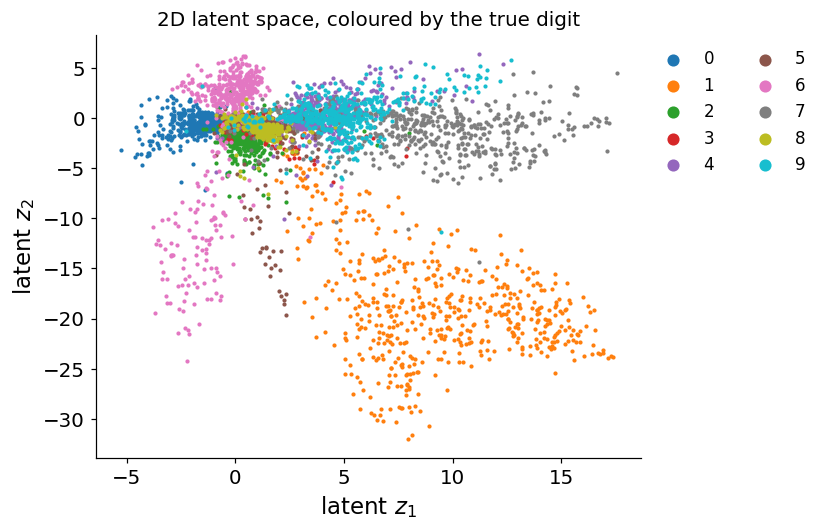

In [7]:
ae2, hist2 = train_autoencoder(DenseAE(d=2, rngs=nnx.Rngs(0)), Xtr_d, epochs=15, seed=0)
L2 = encode(ae2, X5_d)                                             # (5000, 2)
nums["ae2_test_mse"] = float(errors(ae2, X5_d).mean())
print("test MSE (d = 2):", round(nums["ae2_test_mse"], 4))

fig, ax = plt.subplots(figsize=(6.4, 5.0))
for d in range(10):
    m = y5 == d
    ax.scatter(L2[m, 0], L2[m, 1], s=3, color=cmap10(d), label=str(d))
ax.legend(markerscale=4, fontsize=11, ncol=2, loc="upper left", bbox_to_anchor=(1.0, 1))
ax.set_xlabel("latent $z_1$"); ax.set_ylabel("latent $z_2$")
ax.set_title("2D latent space, coloured by the true digit", fontsize=13)
save(fig, "gen_ae_latent_mnist.png"); plt.show()

Some digits occupy their own region of the plane (look at the 0s and the 1s), others overlap. The plane is not a map with a fixed scale: the encoder is free to stretch it, and another seed rotates or mirrors it.

### Sixteen latent numbers

Two numbers are a severe compression. With $d=16$ the reconstructions become much sharper. The figure shows test digits (top), their reconstructions from $16$ numbers (middle) and from $2$ numbers (bottom).

  epoch   1: training loss 0.05061   (  1.3 s)


  epoch   5: training loss 0.01610   (  4.3 s)


  epoch  10: training loss 0.01347   (  9.0 s)


  epoch  15: training loss 0.01227   ( 13.0 s)
test MSE (d = 16): 0.0121 | (d = 2): 0.0389


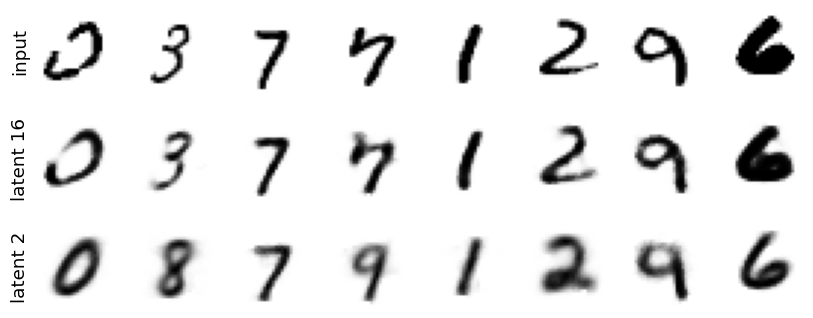

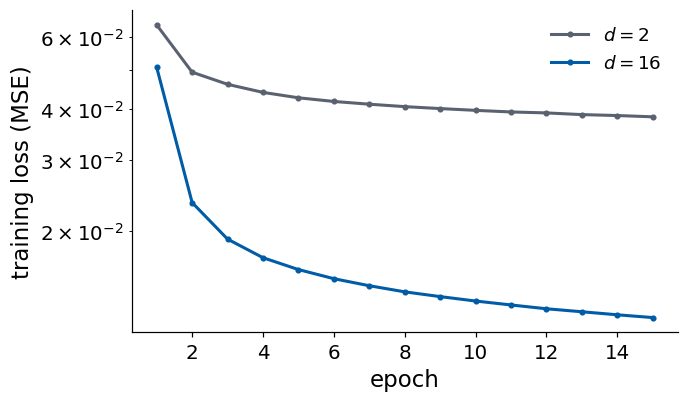

In [8]:
ae16, hist16 = train_autoencoder(DenseAE(d=16, rngs=nnx.Rngs(1)), Xtr_d, epochs=15, seed=1)
err16_X5 = errors(ae16, X5_d)
nums["ae16_test_mse"] = float(err16_X5.mean())
print("test MSE (d = 16):", round(nums["ae16_test_mse"], 4), "| (d = 2):", round(nums["ae2_test_mse"], 4))

show = X5[:8]
r16, r2 = reconstruct(ae16, X5_d[:8]), reconstruct(ae2, X5_d[:8])
fig, axs = plt.subplots(3, 8, figsize=(9, 3.6))
for j in range(8):
    for i, (img, lab) in enumerate([(show[j], "input"), (r16[j], "latent 16"), (r2[j], "latent 2")]):
        axs[i, j].imshow(img.reshape(28, 28), cmap="gray_r"); noframe(axs[i, j])
        if j == 0: axs[i, j].set_ylabel(lab, fontsize=12)
save(fig, "gen_ae_reconstructions.png"); plt.show()

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(np.arange(1, 16), hist2, "o-", color=UJGray, ms=3, label="$d=2$")
ax.plot(np.arange(1, 16), hist16, "o-", color=UJBlue, ms=3, label="$d=16$")
ax.set_xlabel("epoch"); ax.set_ylabel("training loss (MSE)"); ax.set_yscale("log"); ax.legend()
plt.show()

### PCA implementation in JAX

How good are these errors? PCA is the best *linear* compression to $d$ numbers, so it is the natural baseline. We compute it in JAX from the eigendecomposition of the $784\times784$ covariance matrix of the training images (`jnp.linalg.eigh` returns the eigenvalues in ascending order, so we reverse them), project each test image on the first $d$ principal directions, $w^{(l)}=\boldsymbol\lambda_l^{\top}(\mathbf x-\bar{\mathbf x})$, and rebuild it as
$$
\hat{\mathbf x}^{\rm PCA}=\bar{\mathbf x}+\sum_{l=1}^{d}w^{(l)}\boldsymbol\lambda_l .
$$
The test error of PCA should be close to its training error, which by Section 2 is the sum of the discarded variances $\sigma_l^2$ divided by $D$; the cell prints both.

In [9]:
xbar = Xtr_d.mean(0)
C = (Xtr_d - xbar).T @ (Xtr_d - xbar) / Xtr_d.shape[0]       # 784 x 784 covariance matrix
sig2, Lam = jnp.linalg.eigh(C)
sig2, Lam = sig2[::-1], Lam[:, ::-1]                         # descending variances sigma_l^2, principal directions lambda_l as columns

def pca_reconstruct(X, d):
    Lam_d = Lam[:, :d]
    return xbar + ((X - xbar) @ Lam_d) @ Lam_d.T

for d in (2, 16):
    nums[f"pca{d}_test_mse"] = float(mse_per_image(X5_d, pca_reconstruct(X5_d, d)).mean())
    nums[f"pca{d}_train_mse_from_eigenvalues"] = float(sig2[d:].sum() / 784)
print("test MSE    PCA       dense autoencoder")
print(f"d =  2      {nums['pca2_test_mse']:.4f}    {nums['ae2_test_mse']:.4f}")
print(f"d = 16      {nums['pca16_test_mse']:.4f}    {nums['ae16_test_mse']:.4f}")
print("PCA training MSE from the discarded variances sigma_l^2, d = 2 and 16:",
      round(nums["pca2_train_mse_from_eigenvalues"], 4), round(nums["pca16_train_mse_from_eigenvalues"], 4))

test MSE    PCA       dense autoencoder
d =  2      0.0557    0.0389
d = 16      0.0268    0.0121
PCA training MSE from the discarded variances sigma_l^2, d = 2 and 16: 0.056 0.0273


The dense autoencoders reconstruct better than PCA with the same number of latent numbers, for $d=2$ and for $d=16$.

### PCA with scikit-learn

The same baseline in scikit-learn takes three lines. `PCA(n_components=16, svd_solver="full")` creates the estimator; `fit(X)` computes the mean image `mean_` and the principal components (the rows of `components_`) from a complete singular value decomposition of the centred training images; `transform(X)` projects images on the components and `inverse_transform(Z)` rebuilds them as $\bar{\mathbf x}+\sum_l w^{(l)}\boldsymbol\lambda_l$. Since a model with 16 components contains the one with 2, we obtain the $d=2$ reconstruction by keeping only the first two rows of `components_`.

Both programs compute the same projection, so the reconstruction errors must agree to float32 precision, and the cell asserts it. scikit-learn normalises the covariance with $n-1$ instead of $n$, so its `explained_variance_` equals our $\sigma_l^2$ times $n/(n-1)$; the fractions `explained_variance_ratio_` are the same.

In [10]:
sk_pca = PCA(n_components=16, svd_solver="full").fit(Xtr)
Z_sk = sk_pca.transform(X5)
for d in (2, 16):
    rec = sk_pca.mean_ + Z_sk[:, :d] @ sk_pca.components_[:d]
    mse_sk = float(np.mean((X5 - rec) ** 2))
    print(f"d = {d:2d}: test MSE  JAX {nums[f'pca{d}_test_mse']:.6f} | scikit-learn {mse_sk:.6f}")
    assert abs(mse_sk - nums[f"pca{d}_test_mse"]) < 1e-4 * nums[f"pca{d}_test_mse"] + 1e-7
assert np.allclose(sk_pca.inverse_transform(Z_sk), sk_pca.mean_ + Z_sk @ sk_pca.components_, atol=1e-5)
n_tr = Xtr.shape[0]
ratio_jax = np.asarray(sig2[:16] / sig2.sum())
print("fraction of variance of the first 4 components: JAX", np.round(ratio_jax[:4], 5),
      "| scikit-learn", np.round(sk_pca.explained_variance_ratio_[:4], 5))
print(f"explained_variance_[0] / sigma_1^2 = {sk_pca.explained_variance_[0] / float(sig2[0]):.6f}   (n/(n-1) = {n_tr / (n_tr - 1):.6f})")
assert np.allclose(sk_pca.explained_variance_ratio_, ratio_jax, rtol=1e-3)

d =  2: test MSE  JAX 0.055712 | scikit-learn 0.055712
d = 16: test MSE  JAX 0.026838 | scikit-learn 0.026838


fraction of variance of the first 4 components: JAX [0.09705 0.07096 0.06169 0.05389] | scikit-learn [0.09705 0.07096 0.06169 0.05389]
explained_variance_[0] / sigma_1^2 = 1.000021   (n/(n-1) = 1.000017)


### Linear autoencoder

The two implementations agree, and PCA is the baseline. Next we train a **linear** autoencoder with $d=2$ (no activations, no sigmoid, input centred with the mean image) and compare it with PCA in two ways: its test MSE, and the **principal angles** between the plane spanned by the columns of its decoder $W_D$ and the plane of $\boldsymbol\lambda_1,\boldsymbol\lambda_2$. If $Q_{\rm AE}$ and $Q_{\rm PCA}$ are orthonormal bases of the two planes, the singular values of $Q_{\rm AE}^\top Q_{\rm PCA}$ are the cosines of the principal angles; both angles are zero exactly when the planes coincide.

In [11]:
class LinearAE(nnx.Module):
    """z = W_E (x - xbar),  xhat = xbar + W_D z  (no biases, no activations)."""
    def __init__(self, d, mean, D=784, *, rngs):
        self.mean = nnx.Variable(mean)                       # a fixed, non-trainable array stored in the model
        self.WE = nnx.Linear(D, d, use_bias=False, rngs=rngs)
        self.WD = nnx.Linear(d, D, use_bias=False, rngs=rngs)
    def encode(self, x, train=False): return self.WE(x - self.mean[...])
    def decode(self, z, train=False): return self.mean[...] + self.WD(z)
    def __call__(self, x, train=False): return self.decode(self.encode(x))

lin2, hist_lin = train_autoencoder(LinearAE(2, xbar, rngs=nnx.Rngs(2)), Xtr_d, epochs=30, seed=2, lr=3e-3, verbose=False)
nums["linear_ae2_test_mse"] = float(errors(lin2, X5_d).mean())

WD = lin2.WD.kernel[...].T                                   # (784, 2): the decoder columns span the AE plane
Q_ae, _ = jnp.linalg.qr(WD)
cosines = jnp.linalg.svd(Q_ae.T @ Lam[:, :2], compute_uv=False)
angles = np.degrees(np.arccos(np.clip(np.asarray(cosines), -1, 1)))
nums["linear_ae2_principal_angles_deg"] = [float(a) for a in angles]
print(f"linear AE (d = 2): test MSE {nums['linear_ae2_test_mse']:.4f}   PCA (d = 2): {nums['pca2_test_mse']:.4f}")
print("principal angles between the linear-AE plane and the PCA plane (degrees):", np.round(angles, 2))
print("first decoder column . lambda_1 and lambda_2 (normalised):", np.round(np.asarray(WD[:, 0] / jnp.linalg.norm(WD[:, 0]) @ Lam[:, :2]), 3))

linear AE (d = 2): test MSE 0.0557   PCA (d = 2): 0.0557
principal angles between the linear-AE plane and the PCA plane (degrees): [0.76 0.97]
first decoder column . lambda_1 and lambda_2 (normalised): [-0.494 -0.869]


The linear autoencoder reaches the PCA error and its plane is (up to a small angle) the plane of the first two principal components; its two decoder columns, however, are not $\boldsymbol\lambda_1$ and $\boldsymbol\lambda_2$ themselves, only some basis of the same plane. The non-linear autoencoder with the same $d$ goes below the PCA error: it compresses better than any projection.

The mean image is stored in the model as an `nnx.Variable`, not an `nnx.Param`. Our training function differentiates only `nnx.Param`, so the mean stays fixed; `variable[...]` reads its value.

#### Exercise

Train the linear autoencoder with $d=16$ and compare with `pca16_test_mse`. Then add a ReLU between its encoder and decoder layers: what happens to the error?

### One digit through the autoencoder

The images of the autoencoder diagram on the slides: a clearly written test digit (the 3 that the $d=16$ autoencoder rebuilds best), its $16$ latent numbers, and its reconstruction.

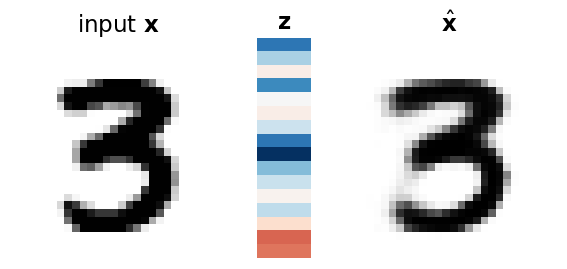

test digit index 4495 | reconstruction error 0.0042 | latent vector: [ -9.64  -4.28   0.9   -8.47  -0.03   0.85  -2.84  -9.59 -13.27  -5.78
  -3.     0.47  -3.34   2.23   7.69   7.12]


In [12]:
threes = np.flatnonzero(y5 == 3)
k3 = threes[np.argmin(err16_X5[threes])]                     # the 3 with the smallest reconstruction error
z3 = encode(ae16, X5_d[k3:k3 + 1])[0]
x_out = reconstruct(ae16, X5_d[k3:k3 + 1])[0]

for arr, name in [(X5[k3], "gen_ae_in.png"), (x_out, "gen_ae_out.png")]:
    fig = plt.figure(figsize=(2, 2)); plt.imshow(arr.reshape(28, 28), cmap="gray_r"); plt.axis("off")
    save(fig, name, pad_inches=0.02); plt.close(fig)
fig, ax = plt.subplots(figsize=(0.13, 0.79))
ax.imshow(z3[:, None], cmap="RdBu_r", vmin=-np.abs(z3).max(), vmax=np.abs(z3).max(), aspect="auto")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(True)
save(fig, "gen_ae_z.png", pad_inches=0.02); plt.close(fig)

fig, axs = plt.subplots(1, 3, figsize=(6.4, 2.6), gridspec_kw=dict(width_ratios=[1, 0.25, 1]))
axs[0].imshow(X5[k3].reshape(28, 28), cmap="gray_r"); axs[0].set_title("input $\\mathbf{x}$")
axs[1].imshow(z3[:, None], cmap="RdBu_r", vmin=-np.abs(z3).max(), vmax=np.abs(z3).max(), aspect="auto"); axs[1].set_title("$\\mathbf{z}$")
axs[2].imshow(x_out.reshape(28, 28), cmap="gray_r"); axs[2].set_title("$\\hat{\\mathbf{x}}$")
for a in axs: noframe(a)
plt.show()
print("test digit index", k3, "| reconstruction error", round(float(err16_X5[k3]), 4), "| latent vector:", np.round(z3, 2))

### Error map of one digit

The per-pixel squared differences $(x_j-\hat x_j)^2$ of this digit show where the reconstruction fails; their mean is the reconstruction error $e(\mathbf x)$ of the image, and the mean of $e$ over all images is the loss $\mathcal L$.

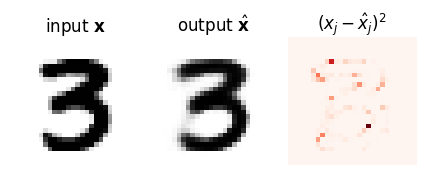

mean of the error map (the reconstruction error of this image): 0.0042


In [13]:
err_map = (X5[k3] - x_out) ** 2
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(3.74, 1.45))
    for a, im, t, cm in zip(axs, [X5[k3], x_out, err_map],
                            [r"input $\mathbf{x}$", r"output $\hat{\mathbf{x}}$", r"$(x_j - \hat{x}_j)^2$"],
                            ["gray_r", "gray_r", "Reds"]):
        a.imshow(im.reshape(28, 28), cmap=cm); a.set_title(t); a.axis("off")
    plt.tight_layout(pad=0.2, w_pad=0.6); save(fig, "gen_ae_loss_map.png"); plt.show()
print("mean of the error map (the reconstruction error of this image):", round(float(err_map.mean()), 4))

<hr/>
## 5. Latent space

Every test image is now described by $16$ latent numbers. We treat them as a new data set: a linear projection with PCA (computed in JAX with a singular value decomposition, SVD, of the centred latent vectors) and a non-linear map with t-SNE. The colours are the true digits, used only for plotting.

Lab 016 implemented t-SNE and k-means in JAX and compared them with scikit-learn; here we use the scikit-learn estimators directly. `TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(Z)` returns the two-dimensional map, and `KMeans(10, n_init=10, random_state=0).fit(Z).labels_` the cluster of every point, the best of 10 k-means++ starts. t-SNE places the points in the plane so that the probabilities of being neighbours, computed from the distances in the 16-dimensional space and in the plane, agree as well as possible (it minimises the Kullback–Leibler divergence between the two sets of probabilities). k-means splits the points into $k$ groups $S_c$ with centres $\boldsymbol\mu_c$ so that the sum of squared distances $\sum_c\sum_{i\in S_c}\lVert\mathbf z_i-\boldsymbol\mu_c\rVert^2$ is as small as possible.

The agreement of a clustering with the true digits is measured by the adjusted Rand index (ARI), `adjusted_rand_score(labels, clusters)`. The Rand index RI is the fraction of pairs of samples on which two partitions agree (both partitions put the pair in the same group, or both in different groups). Even random groups agree on many pairs, so the ARI corrects for chance, $\mathrm{ARI}=(\mathrm{RI}-\mathbb E[\mathrm{RI}])/(1-\mathbb E[\mathrm{RI}])$, with $\mathbb E[\mathrm{RI}]$ the mean of RI over random partitions with the same group sizes: ARI $=1$ for a perfect match and about $0$ for a random assignment (Lab 016, Section 4.6).

The question is whether the digits form clusters *in the latent space itself*. We run k-means ($k=10$) directly on the $16$ latent numbers and on their t-SNE map, and compare with k-means on the pixels (on $50$ PCA components).

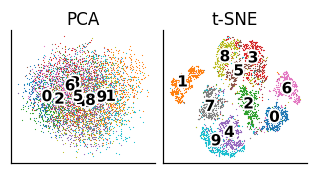

k-means (k = 10), adjusted Rand index with the true digits:
  pixels, 50 PCA components : 0.384
  16 latent numbers, directly: 0.284
  t-SNE map of the 16 latent numbers: 0.696


In [14]:
def pca_2d(Z):
    """Projection on the first two principal components, via the SVD of the centred data (in JAX)."""
    Zc = jnp.asarray(Z) - jnp.mean(jnp.asarray(Z), 0)
    _, s, Vt = jnp.linalg.svd(Zc, full_matrices=False)
    return np.asarray(Zc @ Vt[:2].T), float((s[:2] ** 2).sum() / (s ** 2).sum())

def tsne(Z):
    return TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(np.asarray(Z))

def kmeans_ari(Z, labels):
    return float(adjusted_rand_score(labels, KMeans(10, n_init=10, random_state=0).fit(np.asarray(Z)).labels_))

def plot_two_maps(P_left, P_right, titles, labels, names=None):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
    for a, P2, t in zip(axs, [P_left, P_right], titles):
        for c in range(10):
            m = labels == c
            a.scatter(P2[m, 0], P2[m, 1], s=3, color=cmap10(c), label=(names[c] if names else str(c)))
        a.set_title(t, fontsize=13); a.set_xticks([]); a.set_yticks([])
    axs[1].legend(markerscale=4, fontsize=11, ncol=2, loc="upper left", bbox_to_anchor=(1.0, 1))
    plt.tight_layout()
    return fig

L16 = encode(ae16, X5_d)                                     # (5000, 16)
L16_pca, _ = pca_2d(L16)
L16_tsne = tsne(L16)
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(2.75, 1.45))
    for a, P2, t in zip(axs, [L16_pca, L16_tsne], ["PCA", "t-SNE"]):
        for c in range(10):
            m = y5 == c; a.scatter(P2[m, 0], P2[m, 1], s=0.6, color=cmap10(c), lw=0)
        for c in range(10):
            a.text(*np.median(P2[y5 == c], 0), str(c), fontsize=10, weight="bold", ha="center", va="center", path_effects=OUTLINE)
        a.set_title(t); a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(pad=0.2, w_pad=0.5); save(fig, "gen_ae_latent16_maps.png"); plt.show()

Z50 = np.asarray((X5_d - xbar) @ Lam[:, :50])                  # the pixels, on 50 principal components
nums["pixels_pca50_kmeans_ari"] = kmeans_ari(Z50, y5)
nums["ae16_latent_kmeans_ari_direct"] = kmeans_ari(L16, y5)
nums["ae16_latent_kmeans_ari_tsne"] = kmeans_ari(L16_tsne, y5)
print("k-means (k = 10), adjusted Rand index with the true digits:")
print(f"  pixels, 50 PCA components : {nums['pixels_pca50_kmeans_ari']:.3f}")
print(f"  16 latent numbers, directly: {nums['ae16_latent_kmeans_ari_direct']:.3f}")
print(f"  t-SNE map of the 16 latent numbers: {nums['ae16_latent_kmeans_ari_tsne']:.3f}")

In the PCA projection the digits overlap: they differ along many of the $16$ directions, and any two of them show only part of it. The t-SNE map keeps the neighbours of each point and shows groups. k-means directly in the latent space does not recover the digits better than on the pixels: the digits are kept in the latent space, but not as the round, equally sized groups that k-means looks for.

#### Exercise

Repeat the analysis with the latent space of the $d=2$ autoencoder (`L2`), where no projection is needed. Is k-means better or worse there?

<hr/>
## 6. Convolutional autoencoders

### A small convolutional autoencoder, $d=2$

A dense layer sees an image as a flat list of $784$ numbers: it does not know which pixels are neighbours. A **convolutional** encoder uses the 2D structure, like the convolutional neural networks (CNNs) of Lecture 4. Here two convolutions with $3\times3$ kernels and stride $2$ ($28\to14\to7$ pixels, $16$ and $32$ channels), then dense layers $32\cdot7\cdot7\to128\to d$. The decoder mirrors it: dense layers back to $32\cdot7\cdot7$, then two **transposed convolutions** with stride $2$ ($7\to14\to28$), the last one with a single channel and a sigmoid.

`nnx.Conv` expects images with the channels last, of shape `(batch, height, width, channels)` (NHWC: number of images, height, width, channels), unlike PyTorch's NCHW, which puts the channels before the height; our MNIST images become `(n, 28, 28, 1)` with a reshape, which costs nothing. `nnx.ConvTranspose(..., strides=2, padding="SAME")` doubles the height and width exactly.

On a CPU a convolutional layer costs far more arithmetic per image than a dense layer of similar size, and its gradient even more. To keep the notebook fast we use few channels and train the convolutional models on a random subset of the training images, for fewer epochs (`N_CONV`, `EPOCHS_CONV` below). To make up for the fewer images we use smaller minibatches of $64$: the same arithmetic per epoch, but four times as many gradient steps. The dense autoencoders above used all $60\,000$ images.

training images: 20000 | epochs: 8


  epoch   1: training loss 0.07243   (100.7 s)


  epoch   5: training loss 0.04875   (157.2 s)


parameters: 413315


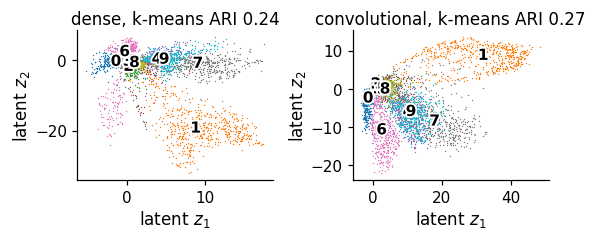

{'ae2_test_mse': 0.0389, 'cae2_test_mse': 0.0445, 'ae2_latent_kmeans_ari': 0.2409, 'cae2_latent_kmeans_ari': 0.2684}


In [15]:
class ConvAE(nnx.Module):
    def __init__(self, d=2, ch=(16, 32), *, rngs):
        c1, c2 = ch
        self.ch = ch
        self.c1 = nnx.Conv(1, c1, (3, 3), strides=2, padding=1, rngs=rngs)           # 28 -> 14
        self.c2 = nnx.Conv(c1, c2, (3, 3), strides=2, padding=1, rngs=rngs)          # 14 -> 7
        self.e1 = nnx.Linear(c2 * 7 * 7, 128, rngs=rngs)
        self.e2 = nnx.Linear(128, d, rngs=rngs)
        self.d1 = nnx.Linear(d, 128, rngs=rngs)
        self.d2 = nnx.Linear(128, c2 * 7 * 7, rngs=rngs)
        self.t1 = nnx.ConvTranspose(c2, c1, (3, 3), strides=2, padding="SAME", rngs=rngs)   # 7 -> 14
        self.t2 = nnx.ConvTranspose(c1, 1, (3, 3), strides=2, padding="SAME", rngs=rngs)    # 14 -> 28

    def encode(self, x, train=False):
        h = nnx.relu(self.c2(nnx.relu(self.c1(x))))
        return self.e2(nnx.relu(self.e1(h.reshape(h.shape[0], -1))))

    def decode(self, z, train=False):
        h = nnx.relu(self.d2(nnx.relu(self.d1(z)))).reshape(-1, 7, 7, self.ch[1])
        return nnx.sigmoid(self.t2(nnx.relu(self.t1(h))))

    def __call__(self, x, train=False):
        return self.decode(self.encode(x, train), train)

Xtr_img, X5_img = Xtr_d.reshape(-1, 28, 28, 1), X5_d.reshape(-1, 28, 28, 1)
N_CONV, EPOCHS_CONV = 20000, 8                              # training subset and epochs for the convolutional models
sub = np.random.default_rng(1).permutation(len(Xtr))[:N_CONV]
Xsub_img = Xtr_img[sub]
print("training images:", Xsub_img.shape[0], "| epochs:", EPOCHS_CONV)
cae2, hist_c2 = train_autoencoder(ConvAE(2, rngs=nnx.Rngs(3)), Xsub_img, epochs=EPOCHS_CONV, seed=3, batch_size=64)
print("parameters:", n_params(cae2))
Lc = encode(cae2, X5_img)
nums["cae2_test_mse"] = float(errors(cae2, X5_img).mean())
nums["ae2_latent_kmeans_ari"] = kmeans_ari(L2, y5)
nums["cae2_latent_kmeans_ari"] = kmeans_ari(Lc, y5)

with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(4.95, 2.05))
    for a, P2, t in zip(axs, [L2, Lc], [f"dense, k-means ARI {nums['ae2_latent_kmeans_ari']:.2f}",
                                        f"convolutional, k-means ARI {nums['cae2_latent_kmeans_ari']:.2f}"]):
        for c in range(10):
            m = y5 == c
            a.scatter(P2[m, 0], P2[m, 1], s=0.8, color=cmap10(c), lw=0)
        for c in range(10):
            a.text(*np.median(P2[y5 == c], 0), str(c), fontsize=10, weight="bold", ha="center", va="center", path_effects=OUTLINE)
        a.set_title(t); a.set_xlabel("latent $z_1$"); a.set_ylabel("latent $z_2$")
    plt.tight_layout(pad=0.2, w_pad=0.8); save(fig, "gen_ae_dense_vs_conv.png"); plt.show()
print({k: round(nums[k], 4) for k in ["ae2_test_mse", "cae2_test_mse", "ae2_latent_kmeans_ari", "cae2_latent_kmeans_ari"]})

With the same two latent numbers the convolutional encoder gives the higher ARI (printed above), although it saw only a third of the training images and has the larger test MSE: it compares neighbouring pixels, as a CNN does, and builds its two numbers from local strokes rather than from individual pixel positions. The colours are not used in training, so a better ARI is a by-product, not a goal, of the reconstruction loss.

### A deeper convolutional autoencoder, $d=16$

A deeper model: three convolutions ($8$, $16$, $32$ channels, the last two with stride $2$), each followed by **batch normalisation** and ReLU, then dense layers $32\cdot7\cdot7\to128\to16$. To save CPU time it is trained on a smaller subset (`N_DEEP` images, `EPOCHS_DEEP` epochs). The decoder mirrors it with transposed convolutions and ends with a $3\times3$ convolution to one channel and a sigmoid.

**Batch normalisation** rescales every channel to zero mean and unit variance over the current minibatch, then applies a learned scale and shift. During training it uses the minibatch statistics and updates running averages of them; at evaluation it uses the running averages, so that the output for one image does not depend on the other images in the batch. In flax the running averages are `nnx.BatchStat` variables, not parameters: they are not differentiated, they are part of `rest` in our training function and are carried through `lax.scan` next to the parameters. The argument `train` selects the mode (`use_running_average=not train`).

  epoch   1: training loss 0.07130   (  8.9 s)


  epoch   5: training loss 0.01287   ( 42.0 s)


parameters: 419249


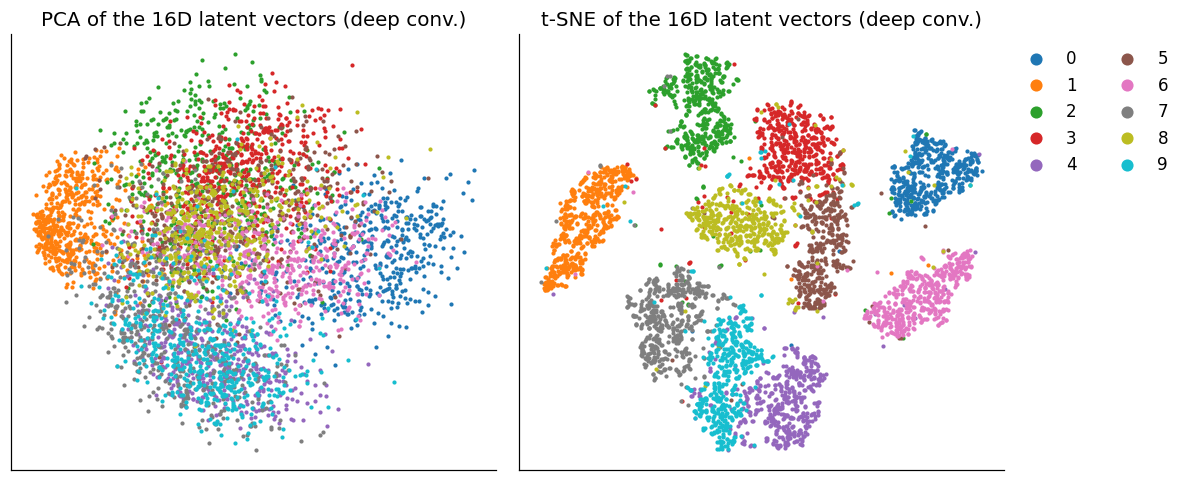

{'ae16_test_mse': 0.0121, 'dcae16_test_mse': 0.0121, 'dcae16_pca2_var': 0.3886, 'ae16_latent_kmeans_ari_direct': 0.2838, 'dcae16_kmeans_ari_direct': 0.4558, 'ae16_latent_kmeans_ari_tsne': 0.6963, 'dcae16_kmeans_ari_tsne': 0.8153}


In [16]:
class DeepConvAE(nnx.Module):
    def __init__(self, d=16, ch=(8, 16, 32), hidden=128, *, rngs):
        c1, c2, c3 = ch
        self.c3 = c3
        conv = lambda i, o, s: nnx.Conv(i, o, (3, 3), strides=s, padding=1, rngs=rngs)
        tconv = lambda i, o: nnx.ConvTranspose(i, o, (3, 3), strides=2, padding="SAME", rngs=rngs)
        self.enc_convs = nnx.List([conv(1, c1, 1), conv(c1, c2, 2), conv(c2, c3, 2)])     # 28 -> 28 -> 14 -> 7
        self.enc_bns = nnx.List([nnx.BatchNorm(c, rngs=rngs) for c in (c1, c2, c3)])
        self.e1, self.e2 = nnx.Linear(c3 * 7 * 7, hidden, rngs=rngs), nnx.Linear(hidden, d, rngs=rngs)
        self.d1, self.d2 = nnx.Linear(d, hidden, rngs=rngs), nnx.Linear(hidden, c3 * 7 * 7, rngs=rngs)
        self.dec_tconvs = nnx.List([tconv(c3, c2), tconv(c2, c1)])                       # 7 -> 14 -> 28
        self.dec_bns = nnx.List([nnx.BatchNorm(c, rngs=rngs) for c in (c2, c1)])
        self.out = conv(c1, 1, 1)

    def encode(self, x, train=False):
        for c, bn in zip(self.enc_convs, self.enc_bns):
            x = nnx.relu(bn(c(x), use_running_average=not train))
        return self.e2(nnx.relu(self.e1(x.reshape(x.shape[0], -1))))

    def decode(self, z, train=False):
        h = nnx.relu(self.d2(nnx.relu(self.d1(z)))).reshape(-1, 7, 7, self.c3)
        for t, bn in zip(self.dec_tconvs, self.dec_bns):
            h = nnx.relu(bn(t(h), use_running_average=not train))
        return nnx.sigmoid(self.out(h))

    def __call__(self, x, train=False):
        return self.decode(self.encode(x, train), train)

N_DEEP, EPOCHS_DEEP = 12000, 6
dcae, hist_d = train_autoencoder(DeepConvAE(16, rngs=nnx.Rngs(4)), Xtr_img[sub[:N_DEEP]], epochs=EPOCHS_DEEP, seed=4, batch_size=64)
print("parameters:", n_params(dcae))
LD = encode(dcae, X5_img)
nums["dcae16_test_mse"] = float(errors(dcae, X5_img).mean())
LD_pca, nums["dcae16_pca2_var"] = pca_2d(LD)
LD_tsne = tsne(LD)
nums["dcae16_kmeans_ari_direct"] = kmeans_ari(LD, y5)
nums["dcae16_kmeans_ari_tsne"] = kmeans_ari(LD_tsne, y5)
fig = plot_two_maps(LD_pca, LD_tsne, ["PCA of the 16D latent vectors (deep conv.)", "t-SNE of the 16D latent vectors (deep conv.)"], y5)
plt.show()
print({k: round(nums[k], 4) for k in ["ae16_test_mse", "dcae16_test_mse", "dcae16_pca2_var",
                                      "ae16_latent_kmeans_ari_direct", "dcae16_kmeans_ari_direct",
                                      "ae16_latent_kmeans_ari_tsne", "dcae16_kmeans_ari_tsne"]})

Compare the two $d=16$ models: the dense one (all training images, $15$ epochs) and the convolutional one (a subset, fewer epochs). The test MSE measures how well each rebuilds the pixels, the ARI how well its latent space groups the digits; the two need not go together, since the loss rewards rebuilding pixels, not separating digits.

#### Exercises

* Train `DeepConvAE` with more channels, e.g. `ch=(32, 64, 128)`, on all $60\,000$ images (best on a GPU). How do the test MSE and the ARI change?
* Remove the batch normalisation layers from `DeepConvAE` (replace `bn(...)` by the identity) and train again with the same seed. How do the training curve and the test MSE change?

<hr/>
## 7. Anomaly detection

An autoencoder trained only on *normal* data rebuilds similar samples well and unusual ones badly. The reconstruction error
$$
s(\mathbf x)=e(\mathbf x)=\frac1D\big\lVert\mathbf x-G_{\boldsymbol\theta_D}\big(E_{\boldsymbol\theta_E}(\mathbf x)\big)\big\rVert^2
$$
is therefore an **anomaly score**: the larger, the more surprising the sample for the model. No example of an anomaly is needed for training. To turn the score into a decision we choose a **threshold** $\tau$ and flag every sample with $s(\mathbf x)>\tau$. A natural choice uses only normal data: $\tau$ = the $95$th percentile of the scores of normal samples, so that $5\%$ of the normal samples are flagged (the false-alarm rate).

To test this idea we train the dense autoencoder ($d=16$, the same architecture and training as above) on all training digits **except the 7s**. For the network every 7 is then an unknown kind of image. We compute the score of all $10\,000$ test digits and ask whether the 7s stand out.

  epoch   1: training loss 0.05458   (  1.1 s)


  epoch   5: training loss 0.01750   (  3.6 s)


  epoch  10: training loss 0.01444   (  6.7 s)


  epoch  15: training loss 0.01303   ( 10.0 s)


mean error: normal digits 0.0128 | 7s 0.0179
threshold (95th percentile of normal digits) 0.0268: flags 0.130 of the 7s
fraction of 7s in the test set 0.103 | 7s among the 16 / 100 largest errors: 3 / 22


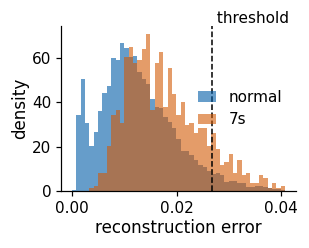

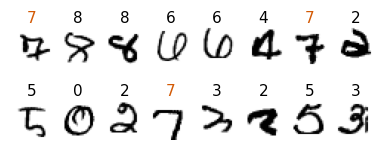

In [17]:
HELD_OUT = 7
aeA, _ = train_autoencoder(DenseAE(d=16, rngs=nnx.Rngs(5)), jnp.asarray(Xtr[ytr != HELD_OUT]), epochs=15, seed=5)
errA = errors(aeA, Xte_d)                                    # anomaly score of every test digit
is7 = yte == HELD_OUT
thr = float(np.percentile(errA[~is7], 95))                   # flags 5% of the normal test digits
nums["anom_err_normal"] = float(errA[~is7].mean())
nums["anom_err_seven"] = float(errA[is7].mean())
nums["anom_threshold"] = thr
nums["anom_frac7_flagged"] = float((errA[is7] > thr).mean())
top = np.argsort(errA)[::-1]
nums["anom_top16_sevens"] = int(is7[top[:16]].sum())
nums["anom_top100_sevens"] = int(is7[top[:100]].sum())
print(f"mean error: normal digits {nums['anom_err_normal']:.4f} | 7s {nums['anom_err_seven']:.4f}")
print(f"threshold (95th percentile of normal digits) {thr:.4f}: flags {nums['anom_frac7_flagged']:.3f} of the 7s")
print(f"fraction of 7s in the test set {is7.mean():.3f} | 7s among the 16 / 100 largest errors: "
      f"{nums['anom_top16_sevens']} / {nums['anom_top100_sevens']}")

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.75, 1.95))
    bins = np.linspace(0, np.percentile(errA, 99.5), 50)
    ax.hist(errA[~is7], bins=bins, density=True, alpha=0.6, color=UJBlue, label="normal")
    ax.hist(errA[is7], bins=bins, density=True, alpha=0.6, color=DSOrange, label="7s")
    ax.axvline(thr, color="k", ls="--", lw=1)
    ax.text(thr, 1.0, " threshold", transform=ax.get_xaxis_transform(), ha="left", va="bottom", fontsize=10)
    ax.set_xlabel("reconstruction error"); ax.set_ylabel("density"); ax.legend(handlelength=1.2, loc="center right")
    ax.ticklabel_format(axis="x", style="plain"); ax.set_xticks([0, 0.02, 0.04])
    save(fig, "gen_anomaly_hist.png"); plt.show()

with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 8, figsize=(4.29, 1.5))
    for j, a in enumerate(axs.ravel()):
        t = top[j]
        a.imshow(Xte[t].reshape(28, 28), cmap="gray_r"); noframe(a)
        a.set_title(f"{yte[t]}", fontsize=10, pad=2, color=DSOrange if is7[t] else "k")
    plt.subplots_adjust(wspace=0.12, hspace=0.35)
    save(fig, "gen_anomaly_top.png"); plt.show()

The two histograms overlap strongly. A 7 shares strokes with 1s and 9s, which the network has seen, so many 7s are rebuilt well. Among the digits with the largest error some are 7s, others are badly written digits of the trained classes: for the autoencoder these are anomalies too.

### ROC curve and AUC

Every threshold $\tau$ gives one decision rule. For each we count

* the **true-positive rate** $\mathrm{TPR}(\tau)=\frac{\#\{\text{anomalies with } s>\tau\}}{\#\{\text{anomalies}\}}$: the fraction of anomalies (here the 7s) found;
* the **false-positive rate** $\mathrm{FPR}(\tau)=\frac{\#\{\text{normal samples with } s>\tau\}}{\#\{\text{normal samples}\}}$: the fraction of normal samples flagged, the false alarms.

Lowering $\tau$ from $+\infty$ to $-\infty$ traces the **ROC curve** (receiver operating characteristic) $\big(\mathrm{FPR}(\tau),\mathrm{TPR}(\tau)\big)$ from $(0,0)$ to $(1,1)$. A useless score lies on the diagonal (as many false alarms as hits); a perfect one goes straight up to $\mathrm{TPR}=1$ at $\mathrm{FPR}=0$.

The **AUC** is the area under the ROC curve. It does not depend on any threshold, and it has a simple probabilistic meaning: if $s_+$ is the score of a randomly chosen anomaly and $s_-$ that of a randomly chosen normal sample,
$$
\mathrm{AUC}=P(s_+>s_-)+\tfrac12P(s_+=s_-) =\frac{1}{n_+n_-}\sum_{a\in+}\sum_{b\in-}\Big[\mathbb 1(s_a>s_b)+\tfrac12\mathbb 1(s_a=s_b)\Big].
$$
$\mathrm{AUC}=\tfrac12$ for chance, $1$ for a perfect separation. (This is the Mann–Whitney $U$ statistic divided by $n_+n_-$.)

### ROC implementation in JAX

Our JAX implementation of the ROC curve sorts the samples by decreasing score: walking down the sorted list is lowering the threshold, and the cumulative counts of anomalies and normal samples give TPR and FPR. Samples with equal scores share one threshold and give one point. The area follows from the trapezoidal rule, and we compare it with the pairwise formula, a single vectorised comparison of all $n_+\times n_-$ pairs; the two must agree, since the trapezoidal area of the ROC curve is exactly the Mann–Whitney statistic.

AUC (trapezoid on the ROC curve) = 0.6958  |  AUC (all 1028 x 8972 pairs) = 0.6958


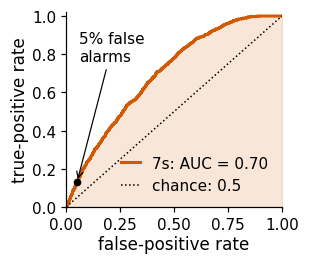

In [18]:
def roc_curve(scores, labels):
    """ROC curve of `scores` for binary `labels` (1 = anomaly). Returns FPR, TPR (from (0,0) to (1,1)) and the thresholds."""
    s, y = jnp.asarray(scores), jnp.asarray(labels, dtype=jnp.float32)
    order = jnp.argsort(-s)                                  # decreasing score = decreasing threshold
    s, y = s[order], y[order]
    tp, fp = jnp.cumsum(y), jnp.cumsum(1.0 - y)              # counts above the threshold placed after each sample
    last_of_tie = jnp.append(s[1:] != s[:-1], True)          # equal scores: one threshold, one point
    tpr = jnp.concatenate([jnp.zeros(1), tp[last_of_tie] / y.sum()])
    fpr = jnp.concatenate([jnp.zeros(1), fp[last_of_tie] / (1.0 - y).sum()])
    return np.asarray(fpr), np.asarray(tpr), np.asarray(s[last_of_tie])

def auc_trapezoid(fpr, tpr):
    return float(jnp.trapezoid(jnp.asarray(tpr), jnp.asarray(fpr)))

@jax.jit
def auc_pairwise(s_pos, s_neg):
    """P(s+ > s-) + P(s+ = s-)/2 over all pairs (Mann-Whitney)."""
    diff = s_pos[:, None] - s_neg[None, :]
    return jnp.mean((diff > 0) + 0.5 * (diff == 0))

fpr, tpr, _ = roc_curve(errA, is7)
nums["anom_auc"] = auc_trapezoid(fpr, tpr)
auc_pairs = float(auc_pairwise(jnp.asarray(errA[is7]), jnp.asarray(errA[~is7])))
print(f"AUC (trapezoid on the ROC curve) = {nums['anom_auc']:.4f}  |  AUC (all {is7.sum()} x {(~is7).sum()} pairs) = {auc_pairs:.4f}")

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.53, 2.3))
    ax.fill_between(fpr, tpr, color=DSOrange, alpha=0.15)
    ax.plot(fpr, tpr, color=DSOrange, lw=2, label=f"7s: AUC = {nums['anom_auc']:.2f}")
    ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance: 0.5")
    ax.plot(0.05, nums["anom_frac7_flagged"], "o", color="k", ms=4)
    ax.annotate("5% false\nalarms", (0.05, nums["anom_frac7_flagged"]), xytext=(0.06, 0.92), fontsize=10, va="top",
                arrowprops=dict(arrowstyle="->", lw=0.8))
    ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(loc="lower right", handlelength=1.2)
    save(fig, "gen_anomaly_roc.png"); plt.show()

The black dot is the decision rule of the histogram: at $5\%$ false alarms it finds the fraction of 7s printed above. An AUC of about $0.7$ means that a randomly chosen 7 has a larger reconstruction error than a randomly chosen normal digit in about seven cases out of ten: a real signal, but a weak one.

### ROC curve and AUC with scikit-learn

The same analysis is available in `sklearn.metrics`. `roc_curve(y_true, y_score)` takes the true binary labels (1 for the positive class, here the anomalies) and the scores, and returns three arrays: the FPR, the TPR and the thresholds, in decreasing order of the threshold, starting from the point $(0,0)$ with the threshold $+\infty$. By default (`drop_intermediate=True`) it removes points that lie on a straight segment of the curve and do not change its shape; with `drop_intermediate=False` it keeps one point per distinct score, which is exactly our construction. `roc_auc_score(y_true, y_score)` returns the area.

Both are deterministic functions of the scores, so they must agree with ours exactly (up to float32 rounding of our cumulative sums), and the cell asserts it: the full curves point by point and the AUC.

In [19]:
fpr_sk, tpr_sk, thr_sk = metrics.roc_curve(is7, errA, drop_intermediate=False)
auc_sk = float(metrics.roc_auc_score(is7, errA))
print(f"points on the curve: JAX {len(fpr)} | scikit-learn {len(fpr_sk)}"
      f" (with drop_intermediate=True: {len(metrics.roc_curve(is7, errA)[0])})")
print(f"largest difference of the curves: FPR {np.abs(fpr_sk - fpr).max():.1e}, TPR {np.abs(tpr_sk - tpr).max():.1e}")
print(f"AUC: JAX {nums['anom_auc']:.6f} | scikit-learn {auc_sk:.6f}")
assert len(fpr_sk) == len(fpr) and np.allclose(fpr_sk, fpr, atol=1e-5) and np.allclose(tpr_sk, tpr, atol=1e-5)
assert abs(auc_sk - nums["anom_auc"]) < 1e-5

points on the curve: JAX 9998 | scikit-learn 9998 (with drop_intermediate=True: 1799)
largest difference of the curves: FPR 3.8e-08, TPR 3.0e-08
AUC: JAX 0.695764 | scikit-learn 0.695764


#### Exercises

* Hold out another digit instead of the 7 (change `HELD_OUT`). Which digits are easy anomalies and which are hard? Can you relate this to the shapes of the digits?
* Use the deep convolutional autoencoder for the anomaly score. Does a model that rebuilds digits better also detect the 7s better?

<hr/>
## 8. CIFAR-10: photographs

CIFAR-10 (Lecture 4) contains $32\times32$ colour photographs in $10$ classes, $50\,000$ for training and $10\,000$ for testing, so $D=32\cdot32\cdot3=3072$. Each image is stored as one row of $3072$ bytes: first the $1024$ red values, then the green, then the blue, each in row-major order. The files are Python pickles; we read them with `pickle` and `numpy`.

train (50000, 3072) test (10000, 3072)


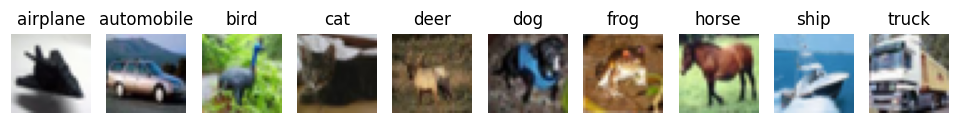

In [20]:
CIFAR_DIR = "data/cifar-10-batches-py"
if not os.path.isdir(CIFAR_DIR):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz", "data/cifar-10-python.tar.gz")
    with tarfile.open("data/cifar-10-python.tar.gz") as tf:
        tf.extractall("data")

def cifar_batch(name):
    with open(os.path.join(CIFAR_DIR, name), "rb") as fh:
        d = pickle.load(fh, encoding="bytes")
    return d[b"data"].astype(np.float32) / 255.0, np.array(d[b"labels"])

parts = [cifar_batch(f"data_batch_{i}") for i in range(1, 6)]
Ctr = np.concatenate([p[0] for p in parts]); cytr = np.concatenate([p[1] for p in parts])
Cte, cyte = cifar_batch("test_batch")
cnames = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
to_img = lambda v: v.reshape(3, 32, 32).transpose(1, 2, 0)        # (3072,) -> (32, 32, 3) for plotting
rc = np.random.default_rng(5)
csel = rc.choice(len(Cte), 5000, replace=False)
C5, cy5 = Cte[csel], cyte[csel]
print("train", Ctr.shape, "test", Cte.shape)

fig, axs = plt.subplots(1, 10, figsize=(11, 1.6))
for c in range(10):
    axs[c].imshow(to_img(Ctr[np.flatnonzero(cytr == c)[0]])); axs[c].set_title(cnames[c], fontsize=11); axs[c].axis("off")
plt.show()

### An autoencoder on CIFAR-10

The same dense architecture, scaled up: $3072\to512\to128\to32$ and back, $10$ epochs. Reconstructions from $32$ latent numbers, and a t-SNE map of the latent vectors of $5000$ test photographs (colours: classes, used only for plotting).

  epoch   1: training loss 0.03776   (  3.6 s)


  epoch   5: training loss 0.01792   ( 16.4 s)


  epoch  10: training loss 0.01620   ( 31.9 s)


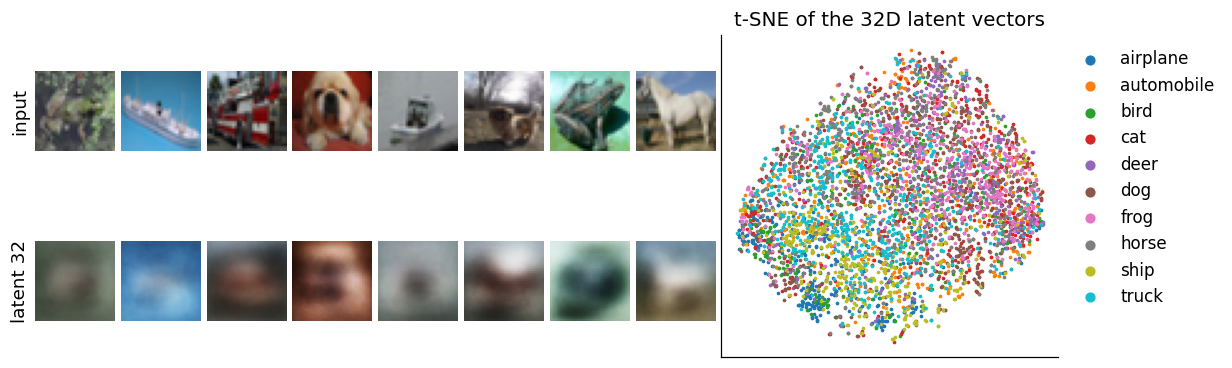

{'cifar_ae_test_mse': 0.0164, 'cifar_ae_latent_kmeans_ari_tsne': 0.0376}


In [21]:
Ctr_d, C5_d = jnp.asarray(Ctr), jnp.asarray(C5)
aeC, _ = train_autoencoder(DenseAE(d=32, D=3072, hidden=(512, 128), rngs=nnx.Rngs(6)), Ctr_d, epochs=10, seed=6)
LC = encode(aeC, C5_d)
RC = reconstruct(aeC, C5_d[:8])
nums["cifar_ae_test_mse"] = float(errors(aeC, C5_d).mean())
LC_tsne = tsne(LC)
nums["cifar_ae_latent_kmeans_ari_tsne"] = kmeans_ari(LC_tsne, cy5)

fig = plt.figure(figsize=(12, 3.8)); gs = fig.add_gridspec(2, 12, wspace=0.08, hspace=0.12)
for j in range(8):
    for r, src in enumerate([C5[j], RC[j]]):
        a = fig.add_subplot(gs[r, j]); a.imshow(np.clip(to_img(src), 0, 1)); noframe(a)
        if j == 0: a.set_ylabel(["input", "latent 32"][r], fontsize=12)
a = fig.add_subplot(gs[:, 8:])
for c in range(10):
    m = cy5 == c
    a.scatter(LC_tsne[m, 0], LC_tsne[m, 1], s=2, color=cmap10(c), label=cnames[c])
a.set_title("t-SNE of the 32D latent vectors", fontsize=13); a.set_xticks([]); a.set_yticks([])
a.legend(markerscale=4, fontsize=11, loc="upper left", bbox_to_anchor=(1.0, 1.0))
save(fig, "gen_cifar_ae.png"); plt.show()
print({k: round(nums[k], 4) for k in ["cifar_ae_test_mse", "cifar_ae_latent_kmeans_ari_tsne"]})

The reconstructions keep the colours and the coarse layout of the scene but lose the details, and the classes do not separate in the latent space: two photographs of the same class can differ in almost every pixel (pose, background, lighting), and a pixel-wise loss puts them far apart.

#### Exercise

Compare with MNIST: why are the CIFAR-10 classes so much harder to separate from the pixels? Train the CNN of Lecture 4 and run t-SNE on its last hidden layer instead.

### Anomaly detection: a clear case

The 7s were a subtle anomaly. Now a very different input: the dense autoencoder trained on **all** MNIST digits ($d=16$, `ae16` from Section 4) receives CIFAR-10 photographs, converted to grayscale with the luminance weights $0.299R+0.587G+0.114B$ and resized from $32\times32$ to $28\times28$ with `jax.image.resize` (bilinear interpolation). The normal samples are the $10\,000$ MNIST test digits, the anomalies the first $5000$ CIFAR-10 test photographs; the threshold again flags $5\%$ of the normal samples. The cell also compares our AUC with `metrics.roc_auc_score`.

threshold 0.0256 flags 0.9984 of the photographs
AUC (trapezoid) 0.9997 | AUC (pairs) 0.9997
median error: digits 0.0110 | photographs 0.2191
AUC: JAX 0.999705 | scikit-learn 0.999705


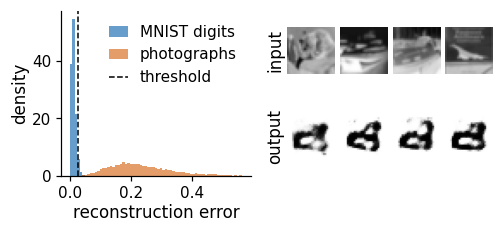

In [22]:
gray = 0.299 * Cte[:5000, :1024] + 0.587 * Cte[:5000, 1024:2048] + 0.114 * Cte[:5000, 2048:]
ood = jax.image.resize(jnp.asarray(gray).reshape(-1, 32, 32), (5000, 28, 28), method="bilinear").reshape(-1, 784)
ood = jnp.clip(ood, 0.0, 1.0)

err_in = errors(ae16, Xte_d)                                 # normal: MNIST test digits
err_ood = errors(ae16, ood)                                  # anomalies: photographs
thr_in = float(np.percentile(err_in, 95))
nums["ood_threshold"] = thr_in
nums["ood_frac_flagged"] = float((err_ood > thr_in).mean())
fpr_o, tpr_o, _ = roc_curve(np.r_[err_in, err_ood], np.r_[np.zeros(len(err_in)), np.ones(len(err_ood))])
nums["ood_auc"] = auc_trapezoid(fpr_o, tpr_o)
nums["ood_auc_pairwise"] = float(auc_pairwise(jnp.asarray(err_ood), jnp.asarray(err_in)))
nums["ood_median_err_digits"] = float(np.median(err_in))
nums["ood_median_err_photos"] = float(np.median(err_ood))
print(f"threshold {thr_in:.4f} flags {nums['ood_frac_flagged']:.4f} of the photographs")
print(f"AUC (trapezoid) {nums['ood_auc']:.4f} | AUC (pairs) {nums['ood_auc_pairwise']:.4f}")
print(f"median error: digits {nums['ood_median_err_digits']:.4f} | photographs {nums['ood_median_err_photos']:.4f}")
auc_ood_sk = float(metrics.roc_auc_score(np.r_[np.zeros(len(err_in)), np.ones(len(err_ood))], np.r_[err_in, err_ood]))
print(f"AUC: JAX {nums['ood_auc']:.6f} | scikit-learn {auc_ood_sk:.6f}")
assert abs(auc_ood_sk - nums["ood_auc"]) < 1e-5

rec_ood = reconstruct(ae16, ood[:4])
with plt.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.06, 1.95))
    gs = fig.add_gridspec(2, 6, width_ratios=[2.2, 0.3, 0.55, 0.55, 0.55, 0.55], wspace=0.08, hspace=0.08)
    ax = fig.add_subplot(gs[:, 0])
    bins = np.linspace(0, np.percentile(np.r_[err_in, err_ood], 99.5), 70)
    ax.hist(err_in, bins=bins, density=True, alpha=0.6, color=UJBlue, label="MNIST digits")
    ax.hist(err_ood, bins=bins, density=True, alpha=0.6, color=DSOrange, label="photographs")
    ax.axvline(thr_in, color="k", ls="--", lw=1, label="threshold")
    ax.set_xlabel("reconstruction error"); ax.set_ylabel("density"); ax.legend(handlelength=1.2)
    for j in range(4):
        for r, src in enumerate([np.asarray(ood[j]), rec_ood[j]]):
            a = fig.add_subplot(gs[r, 2 + j]); a.imshow(src.reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
            noframe(a)
            if j == 0: a.set_ylabel(["input", "output"][r])
    save(fig, "gen_anomaly_ood.png"); plt.show()

The two populations barely overlap, and the reconstructions of the photographs look like blurred digits: the decoder can only produce what it has learned. An anomaly far from the training data is easy to detect, one that resembles it is hard; the two ROC curves side by side show the difference.

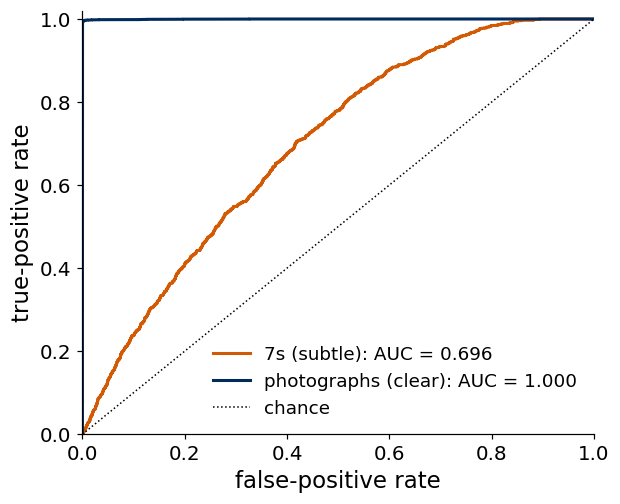

In [23]:
fig, ax = plt.subplots(figsize=(6.0, 5.0))
ax.plot(fpr, tpr, color=DSOrange, lw=2, label=f"7s (subtle): AUC = {nums['anom_auc']:.3f}")
ax.plot(fpr_o, tpr_o, color=UJNavy, lw=2, label=f"photographs (clear): AUC = {nums['ood_auc']:.3f}")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance")
ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="lower right"); plt.show()

### The idea in one figure

The autoencoder trained on all digits rebuilds a digit well: small reconstruction error. A photograph is unlike anything it was trained on: the decoder can only produce digit-like images, the error is large, and the photograph is flagged. We show a typical case of each: the digit and the photograph whose errors are the medians of their groups. The two error maps share one colour scale.

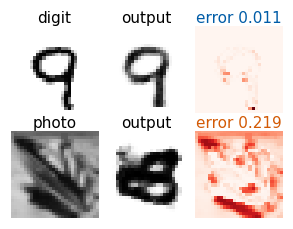

errors shown: 0.011 0.2191


In [24]:
kd = np.argsort(err_in)[len(err_in) // 2]                    # median digit
ko = np.argsort(err_ood)[len(err_ood) // 2]                  # median photograph
xd_, xo_ = Xte[kd], np.asarray(ood[ko])
rd_, ro_ = reconstruct(ae16, Xte_d[kd:kd + 1])[0], reconstruct(ae16, ood[ko:ko + 1])[0]
vmax = max(((xd_ - rd_) ** 2).max(), ((xo_ - ro_) ** 2).max())

with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(2.53, 1.95))
    for r, (xin, xr, e, lab) in enumerate([(xd_, rd_, err_in[kd], "digit"), (xo_, ro_, err_ood[ko], "photo")]):
        for c, (im, cm) in enumerate([(xin, "gray_r"), (xr, "gray_r"), ((xin - xr) ** 2, "Reds")]):
            axs[r, c].imshow(im.reshape(28, 28), cmap=cm, vmin=0, vmax=(vmax if c == 2 else 1)); noframe(axs[r, c])
        axs[r, 0].set_title(lab, fontsize=10, pad=2); axs[r, 1].set_title("output", fontsize=10, pad=2)
        axs[r, 2].set_title(f"error {e:.3f}", fontsize=10, pad=2, color=(DSOrange if r else UJBlue))
    plt.tight_layout(pad=0.2, w_pad=0.3, h_pad=0.5); save(fig, "gen_anomaly_idea.png"); plt.show()
nums["idea_err_digit"] = float(err_in[kd]); nums["idea_err_photo"] = float(err_ood[ko])
print("errors shown:", round(nums["idea_err_digit"], 4), round(nums["idea_err_photo"], 4))

#### Exercises

* Feed the MNIST autoencoder other inputs: digits rotated by $90°$, inverted images $1-\mathbf x$, uniform noise, or the Fashion-MNIST clothes. Order them by their AUC against the MNIST test digits.
* The reconstruction error is not the only possible score. Fit a Gaussian to the latent vectors $\mathbf z$ of the training digits and use the Mahalanobis distance of $\mathbf z$ as the score. Is it better for the 7s?

<hr/>
## 9. Summary

An autoencoder is an encoder and a decoder trained together to rebuild their input through a bottleneck of $d$ numbers. The loss is the pixel-wise MSE, so no labels are needed, and the bottleneck acts as a learned, lossy compression. A linear autoencoder spans the PCA subspace, while non-linear layers compress better than any projection.

The latent space keeps the structure of the data, in the sense that similar images get nearby $\mathbf z$, but its geometry is not designed for clustering; convolutional encoders, which see neighbouring pixels, separate the digits better. The reconstruction error of an autoencoder trained on normal data is an anomaly score. The ROC curve shows all thresholds at once, and the AUC is the probability that an anomaly scores higher than a normal sample. Anomalies far from the training data, such as photographs for an MNIST autoencoder, are easy to detect; anomalies that resemble the training data, such as a held-out digit, are hard.